# Stabilized Newton-Raphson method past a limit point

The load-controlled Newton-Raphson method fails where there is no
equilibrium near the last converged state at a larger load factor: at a
limit point, a local fold of the equilibrium path or a jump to another
buckling pattern. `NL_method='stabilized_NR'`, described in
[stabilized_newton_raphson._solver_stabilized_NR](../stabilized_newton_raphson.rst),
keeps the load control and solves each increment in up to three stages:

1. the Newton-Raphson iterations of
   $\boldsymbol{R} = \boldsymbol{F}_{int}(\boldsymbol{c}) - \lambda_{n+1} \boldsymbol{F}_{ext} = \boldsymbol{0}$;
2. if they fail, the iterations of the equilibrium with viscous forces in
   the pseudo-time of the load factor,

$$
\boldsymbol{F}_{int}(\boldsymbol{c})
+ \frac{\mu}{\Delta\lambda} \boldsymbol{D} (\boldsymbol{c} - \boldsymbol{c}_n)
- \lambda_{n+1} \boldsymbol{F}_{ext} = \boldsymbol{0}
$$

   with $\boldsymbol{D}$ the absolute values of the diagonal of the linear
   stiffness matrix and $\mu$ = `Analysis.stabilization_factor`;
3. if these converge, the Newton-Raphson iterations of $\boldsymbol{R}$
   again, from the damped state.

`Analysis.stabilization_status` records each accepted state as
`'undamped'` (stage 1), `'corrected'` (stage 3), both equilibria to the
tolerance, or `'damped'` (stage 3 failed), a state that is not an
equilibrium, whose relative residual is in `Analysis.damped_residuals`.

This notebook uses the von Mises truss of `tests/analytic_problems.py`,
whose equilibrium path is known in closed form, loaded beyond its limit
load.

In [1]:
%matplotlib inline
import os
import sys

# the helper functions of the tests are imported from the folder tests/
sys.path.insert(0, os.path.join('..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt

from structsolve.convergence import crisfield_weights, crisfield_zeta
from analytic_problems import von_mises_truss

## The model and the closed-form references

The apex deflection $w$ (DOF 0) of the shallow truss has the internal force
$f(w) = w^3 - 3 w^2 + 2 w$, and the truss is loaded through a spring of
stiffness $k_s = 10$ by the force $\lambda \alpha F_{lim}$, a multiple
$\alpha$ of the limit load $F_{lim} = 2/(3\sqrt{3})$, reached at
$w_{lim} = 1 - 1/\sqrt{3}$. Along the equilibrium path
$\lambda(w) = f(w)/(\alpha F_{lim})$: the load factor reaches its maximum
$1/\alpha$ at the limit point and, for $\alpha > 1$, the only equilibrium
at $\lambda = 1$ is on the inverted configuration, the largest real root
of $f(w) = \alpha F_{lim}$. Under load control the solution must jump from
the limit point to the inverted configuration.

In [2]:
F_LIM = 2/(3*np.sqrt(3))
W_LIM = 1 - 1/np.sqrt(3)


def w_final(frac):
    # apex deflection at lambda = 1: the largest real root of the cubic
    r = np.roots([1., -3., 2., -frac*F_LIM])
    return r[np.abs(r.imag) < 1e-12].real.max()


def zeta(p, lbd, c):
    # Crisfield's relative residual of the undamped equilibrium
    fint = p.fint(c)
    return crisfield_zeta(fint - lbd*p.fext, lbd*p.fext, fint,
                          crisfield_weights(p.kC))


def run(frac, initialInc, **kwargs):
    p = von_mises_truss(frac=frac, ks=10.)
    p.analysis(initialInc=initialInc, **kwargs)
    p.an.static(NLgeom=True, silent=True)
    return p


def print_states(p):
    an = p.an
    print(f"{'inc':>3}  {'lambda':>8}  {'w':>8}  {'status':>9}  {'zeta':>9}")
    for i, (lbd, c, s) in enumerate(zip(an.increments, an.cs,
                                        an.stabilization_status)):
        print(f'{i:3d}  {lbd:8.5f}  {c[0]:8.5f}  {s:>9}  {zeta(p, lbd, c):9.2e}')

## Newton-Raphson stops at the limit point

With $\alpha = 1.3$ and load increments starting at 0.1, the plain method
converges up to the limit point, $\lambda = 1/1.3 = 0.7692$, then cuts every
increment down to `minInc` and stops:

In [3]:
frac = 1.3
nr = run(frac, 0.1, NL_method='NR')
print(f'NR: {len(nr.an.increments)} increments, last load factor '
      f'{nr.an.increments[-1]:.5f} (limit point {1/frac:.5f}), '
      f'w = {nr.an.cs[-1][0]:.5f} (w_lim = {W_LIM:.5f}), '
      f'{len(nr.fint_calls)} evaluations of fint')

NR: 12 increments, last load factor 0.76918 (limit point 0.76923), w = 0.41870 (w_lim = 0.42265), 152 evaluations of fint


## The stabilized method passes it

The same analysis with `NL_method='stabilized_NR'` and the default
$\mu = 10^{-5}$: the increment that fails at stage 1 converges with the
viscous forces and is corrected to the equilibrium on the inverted
configuration, after which the plain iterations converge again up to
$\lambda = 1$. Every accepted state satisfies the undamped equilibrium,
$\zeta \le$ `relTOL` $= 10^{-9}$:

In [4]:
st = run(frac, 0.1, NL_method='stabilized_NR')
print(f'stabilized_NR: {len(st.an.increments)} increments, '
      f'{len(st.fint_calls)} evaluations of fint, '
      f'stabilization_factor = {st.an.stabilization_factor:g}')
print_states(st)
w_ref = w_final(frac)
w = st.an.cs[-1][0]
print(f'\nw at lambda = 1: computed {w:.10f}, closed form {w_ref:.10f}, '
      f'rel. diff. {abs(w - w_ref)/w_ref:.2e}')

stabilized_NR: 6 increments, 113 evaluations of fint, stabilization_factor = 1e-05
inc    lambda         w     status       zeta
  0   0.10000   0.02603   undamped   1.37e-10
  1   0.25000   0.06966   undamped   2.22e-16
  2   0.47500   0.15155   undamped   4.64e-12
  3   0.64375   0.24149   undamped   1.40e-15
  4   0.89688   2.17549  corrected   7.57e-13
  5   1.00000   2.19160   undamped   1.64e-15

w at lambda = 1: computed 2.1916014756, closed form 2.1916014756, rel. diff. 4.05e-16


## Damped-only states

The result depends on the load, on $\mu$ and on the increments. With
$\alpha = 1.05$, load increments starting at 0.2 and the default $\mu$, the
plain method stops at the limit point, $\lambda = 1/1.05 = 0.9524$, and the
stabilized method passes it, but the correction fails at two increments
after the limit point: their damped states are kept and flagged. Their residual is the viscous force,
$\boldsymbol{R} = -(\mu/\Delta\lambda) \boldsymbol{D} (\boldsymbol{c} - \boldsymbol{c}_n)$
to the tolerance, and `damped_residuals` gives its relative size, here
0.11 % and 0.31 %: these states are not equilibria, and they lie off
the equilibrium path, beyond the limit load. From the last damped state
the plain iterations of the next increment converge on the inverted
configuration, and the analysis reaches its equilibrium at $\lambda = 1$:

In [5]:
frac2 = 1.05
dm = run(frac2, 0.2, NL_method='stabilized_NR')
mu = dm.an.stabilization_factor
print(f'stabilized_NR: {len(dm.an.increments)} increments, '
      f'{len(dm.fint_calls)} evaluations of fint')
print_states(dm)
nr2 = run(frac2, 0.2, NL_method='NR')
print(f'NR: last load factor {nr2.an.increments[-1]:.5f}')
D = np.abs(np.diag(dm.kC))
an = dm.an
lbds = [0.] + an.increments
cs = [np.zeros(2)] + an.cs
print()
for i, s in enumerate(an.stabilization_status):
    if s == 'damped':
        R = dm.fint(cs[i + 1]) - lbds[i + 1]*dm.fext
        viscous = mu/(lbds[i + 1] - lbds[i])*D*(cs[i + 1] - cs[i])
        print(f'inc {i:2d}: damped_residuals = {an.damped_residuals[i]:.3e}, '
              f'max|R + viscous force| / max|viscous force| = '
              f'{np.abs(R + viscous).max()/np.abs(viscous).max():.1e}')
w_ref2 = w_final(frac2)
print(f'\nw at lambda = 1: computed {an.cs[-1][0]:.10f}, closed form '
      f'{w_ref2:.10f}, rel. diff. {abs(an.cs[-1][0] - w_ref2)/w_ref2:.2e}')

stabilized_NR: 14 increments, 377 evaluations of fint
inc    lambda         w     status       zeta
  0   0.20000   0.04317   undamped   9.30e-16
  1   0.50000   0.12269   undamped   1.47e-12
  2   0.95000   0.39924   undamped   1.84e-15
  3   0.95313   0.40846     damped   1.14e-03
  4   0.95625   0.43353     damped   3.08e-03
  5   0.95781   2.15543   undamped   3.86e-13
  6   0.95938   2.15564   undamped   7.21e-15
  7   0.96094   2.15585   undamped   9.44e-14
  8   0.96328   2.15617   undamped   3.13e-13
  9   0.96680   2.15664   undamped   1.48e-12
 10   0.97207   2.15734   undamped   7.43e-12
 11   0.97998   2.15840   undamped   3.70e-11
 12   0.99185   2.15998   undamped   1.83e-10
 13   1.00000   2.16107   undamped   8.65e-11
NR: last load factor 0.95230

inc  3: damped_residuals = 1.142e-03, max|R + viscous force| / max|viscous force| = 1.0e-06
inc  4: damped_residuals = 3.083e-03, max|R + viscous force| / max|viscous force| = 8.8e-09

w at lambda = 1: computed 2.1610686292, c

## The paths

The closed-form equilibrium path $\lambda(w)$, with the states of the plain
and of the stabilized method. The stabilized states jump at the limit load
from the softening branch to the inverted configuration; the damped-only
states lie off the equilibrium path.

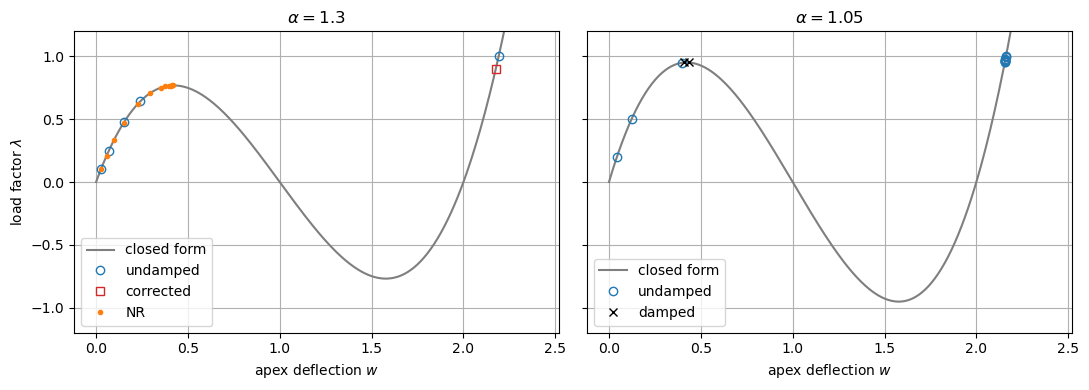

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ws = np.linspace(0., 2.4, 400)
markers = {'undamped': ('o', 'C0'), 'corrected': ('s', 'C3'),
           'damped': ('x', 'k')}
for ax, f, p, title in ((axes[0], frac, st, r'$\alpha = 1.3$'),
                        (axes[1], frac2, dm, r'$\alpha = 1.05$')):
    ax.plot(ws, (ws**3 - 3*ws**2 + 2*ws)/(f*F_LIM), 'C7-',
            label='closed form')
    for s, (m, col) in markers.items():
        pts = [(c[0], l) for l, c, si in zip(p.an.increments, p.an.cs,
                                             p.an.stabilization_status)
               if si == s]
        if pts:
            x, y = np.array(pts).T
            ax.plot(x, y, m, color=col, label=s, mfc='none')
    ax.set_xlabel('apex deflection $w$')
    ax.set_title(title)
    ax.set_ylim(-1.2, 1.2)
    ax.grid(True)
axes[0].plot([c[0] for c in nr.an.cs], nr.an.increments, '.', color='C1',
             label='NR')
axes[0].set_ylabel(r'load factor $\lambda$')
axes[0].legend()
axes[1].legend()
plt.tight_layout()

## Stability of the accepted states

The scheme finds an equilibrium beyond the jump, not necessarily the one a
dynamic process reaches, and it does not check its stability. With
`inertia=True` the sign of the determinant of the tangent stiffness matrix
is recorded at every accepted state. It is $+1$ at every state here,
which a stable state requires; an even number of negative eigenvalues
gives the same sign, and their count requires `linear_solver='pardiso'`
or `inertia_num_eigvals`.

In [7]:
si = run(frac, 0.1, NL_method='stabilized_NR', inertia=True)
for lbd, c, s, d in zip(si.an.increments, si.an.cs,
                        si.an.stabilization_status, si.an.det_signs):
    print(f'lambda {lbd:.5f}, w {c[0]:8.5f}, {s:>9}, det sign {d:+d}')

lambda 0.10000, w  0.02603,  undamped, det sign +1
lambda 0.25000, w  0.06966,  undamped, det sign +1
lambda 0.47500, w  0.15155,  undamped, det sign +1
lambda 0.64375, w  0.24149,  undamped, det sign +1
lambda 0.89688, w  2.17549, corrected, det sign +1
lambda 1.00000, w  2.19160,  undamped, det sign +1
